In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6573


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7027


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### HALの時系列データを取得

In [7]:
hal = 'HAL'

response = request_api.update_stock_timeseries_data(
    code=hal,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
hal_timeseries_df = request_api.get_stock_time_series_data(
    code=hal,
    market=None,
    start=start,
    end=end
)
hal_timeseries_df

取得件数: 7027


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1104037,HAL,None,1998-11-17,10.282387,10.502011,9.982900,10.182558,4252400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1104038,HAL,None,1998-11-18,10.142623,10.382212,9.783239,10.362247,5614200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1104039,HAL,None,1998-11-19,10.222487,10.382214,10.142624,10.302351,3288600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1104040,HAL,None,1998-11-20,10.561905,10.921289,10.282384,10.302350,6597000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1104041,HAL,None,1998-11-23,10.442111,10.581872,9.982898,10.541940,7497600,10.338289,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7022,1322454,HAL,None,2026-10-20,33.590000,33.830002,32.860001,33.299999,19439200,33.135999,...,32.041376,-40.066593,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7023,1322455,HAL,None,2026-10-21,33.990002,34.029999,33.290001,33.509998,12080400,33.267999,...,32.127492,-45.795270,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7024,1332289,HAL,None,2026-10-22,33.189999,34.410000,32.349998,34.299999,14288200,33.575999,...,32.132421,-50.260394,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7025,1332290,HAL,None,2026-10-23,34.919998,35.270000,33.290001,33.459999,12710400,33.603999,...,32.136491,-49.816443,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Halliburton Company"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=hal,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 662


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{hal}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/HAL_2025-01-01_2026-10-27.png


#### 株価のみのチャート

In [12]:
name = "Halliburton Company"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
#end = dt.datetime(2026, 4, 17).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=hal,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 662


### WTI

In [13]:
name = "WTI指数"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=wti,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 664


In [14]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{wti}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/CL=F_2025-01-01_2026-10-27.png


#### 時系列データを保存

In [15]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{hal}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
hal_df = hal_timeseries_df.copy()
hal_df = hal_df.reset_index()
hal_df["date"] = pd.to_datetime(hal_df["date"])
hal_df = hal_df.set_index("date")
hal_df = hal_df.loc['2026-01-01':end]
hal_df.to_csv(output_path)
hal_df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1110859,HAL,None,29.196999,29.483049,27.825922,27.954153,7818800,27.859461,...,26.415732,66.259711,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6823,1110860,HAL,None,31.485413,32.580299,30.765352,31.564323,47339000,28.638705,...,26.444518,66.259711,True,NaN,NaN,-0.62464,NaN,NaN,NaN,False
2026-01-06,6824,1110861,HAL,None,30.410254,31.672827,30.222840,31.327592,24490600,29.382440,...,26.591899,66.251174,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1110862,HAL,None,29.966379,30.696306,29.759239,30.617395,17100300,29.917061,...,26.757881,67.250064,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1110863,HAL,None,31.732006,31.860237,30.321477,30.439844,19696300,30.380662,...,26.918622,69.239307,True,NaN,NaN,NaN,NaN,NaN,NaN,False


In [16]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{wti}_data_{dt.datetime.now().strftime("%Y-%m-%d")}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
wti_df = wti_df.copy()
wti_df = wti_df.reset_index()
wti_df["date"] = pd.to_datetime(wti_df["date"])
wti_df = wti_df.set_index("date")
wti_df = wti_df.loc['2026-01-01':end]
wti_df.to_csv(output_path)
wti_df.head()

,index,id,commodity_id,commodity_code,commodity_market,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6367,12897,2,CL=F,None,57.320000,57.930000,56.599998,57.410000,None,...,-62.837607,-62.080594,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6368,12898,2,CL=F,None,58.320000,58.509998,56.310001,57.470001,None,...,-61.880342,-69.525314,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6369,12899,2,CL=F,None,57.130001,58.869999,56.840000,58.340000,None,...,-61.059829,-76.893196,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6370,12900,2,CL=F,None,55.990002,57.169998,55.759998,57.000000,None,...,-59.623932,-84.465978,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6371,12901,2,CL=F,None,57.759998,58.740002,55.970001,56.419998,None,...,-58.871795,-85.336805,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(30.83688640047613),
  '1.272': np.float64(27.472805804948827),
  '1.382': np.float64(26.112332034698813),
  '1.618': np.float64(23.193497400344242)},
 'fib_levels_up': {'1.272': np.float64(46.568910361912636),
  '1.382': np.float64(47.929384132162646),
  '1.618': np.float64(50.84821876651722),
  '2.000': np.float64(55.57277313229453)},
 'swing_high': np.float64(43.20482976638533),
 'swing_low': np.float64(30.83688640047613),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6822  1110859        HAL         None  29.196999  29.483049   
 1   2026-01-05   6823  1110860        HAL         None  31.485413  32.580299   
 2   2026-01-06   6824  1110861        HAL         None  30.410254  31.672827   
 3   2026-01-07   6825  1110862        HAL         None  29.966379  30.696306   
 4   2026-01-08   6826  1110863        HAL         None  31.732006  31.860237   
 ..         ...    ...      .

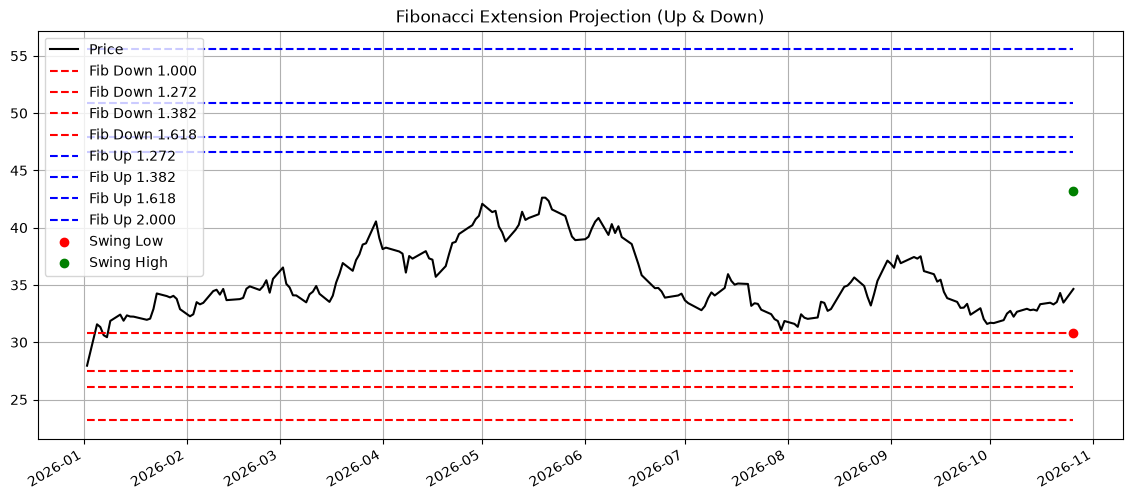

In [17]:
fib_result = fibonacci_extension.compute_fibonacci_extension(hal_df.copy().reset_index())
fib_result

In [18]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{hal}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/HAL_fibonacci_extension_2026-10-27.png


#### 財務データ

In [19]:
response = request_api.update_corp_finance_data(
    code=hal,
    market=None
)
response

{'result': True}

In [20]:
hal_financials_data = request_api.get_corp_financials_data(code=hal, market=None)
hal_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=hal, market=None)
hal_cash_flow_data = request_api.get_corp_cash_flow_data(code=hal, market=None)
hal_earnings_data = request_api.get_corp_earnings_data(code=hal, market=None)
hal_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=hal, market=None)

In [21]:
# ４年分の財務データ
hal_financials_data_df = pd.DataFrame(hal_financials_data['results'])
# ４年分のバランスシート
hal_balance_sheet_data_df = pd.DataFrame(hal_balance_sheet_data['results'])
# ４年分のキャッシュフロー
hal_cash_flow_data_df = pd.DataFrame(hal_cash_flow_data['results'])
# ４年分の収益データ
hal_earnings_data_df = pd.DataFrame(hal_earnings_data['results'])
# ４年分の四半期収益データ
hal_quarterly_earnings_data_df = pd.DataFrame(hal_quarterly_earnings_data['results'])

In [22]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=hal,
    market=None,
    bs_df=hal_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,12.736855,NaN,NaN,24.262755,3.796047,2.137366
1,21.739542,2.317435e+10,1.066000e+09,40.236976,16.126995,0.885195
2,32.176433,3.426957e+10,1.065052e+09,40.952520,21.397701,1.010690
3,32.851463,3.498681e+10,1.065000e+09,40.952520,24.436652,0.984877
4,34.716295,3.692432e+10,1.063602e+09,39.174836,18.059470,1.161468


In [23]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = hal,
    market = None,
)
financial_df.to_markdown()

取得件数: 6953


'|    | date                |      revenue |    earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |    EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|-------------:|------------:|---------------:|-------------:|----------------------------:|----------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan          | nan         |   nan          |  nan         |                 nan         | 0         |        nan         |      nan    |        nan    |           nan         |      nan         |\n|  1 | 2022-12-31 00:00:00 |   2.0297e+10 |   1.572e+09 |     2.3255e+10 |    8.943e+09 |                   2.346e+09 | 3.542e+09 |          3.073e+09 |        1.74 |          1.74 |             2.242e+09 |        1.231e+09 |\n|  2 | 2023-12-31 00:00:00 |   2.3018e+10 |   2.638e+09 |     2.4683e+10 |    8.809e+09 |  